<a href="https://colab.research.google.com/github/Anshika425/Budget_Tracker_Project/blob/main/Budget_Tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Budget Tracker Analysis

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
folder = "/content/drive/MyDrive/Budget_Tracker_Project"
os.makedirs(folder, exist_ok=True)
print("Folder ready:", folder)

Mounted at /content/drive
Folder ready: /content/drive/MyDrive/Budget_Tracker_Project


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data = [
    ("2026-09-01", "Pocket Money", "Income", 15000),
    ("2026-09-03", "Food", "Expense", 1200),
    ("2026-09-05", "Travel", "Expense", 600),
    ("2026-09-10", "Shopping", "Expense", 2500),
    ("2026-09-15", "Education", "Expense", 1800),
    ("2026-09-20", "Entertainment", "Expense", 700),
    ("2026-09-25", "Food", "Expense", 900),
    ("2026-10-01", "Pocket Money", "Income", 15000),
    ("2026-10-02", "Food", "Expense", 1500),
    ("2026-10-06", "Travel", "Expense", 800),
    ("2026-10-12", "Shopping", "Expense", 3000),
    ("2026-10-18", "Entertainment", "Expense", 1000),
    ("2026-10-22", "Education", "Expense", 2000),
    ("2026-10-28", "Bills", "Expense", 1200),
    ("2026-11-01", "Pocket Money", "Income", 15000),
    ("2026-11-04", "Food", "Expense", 1300),
    ("2026-11-09", "Travel", "Expense", 700),
    ("2026-11-14", "Shopping", "Expense", 2200),
    ("2026-11-18", "Bills", "Expense", 1200),
    ("2026-11-19", "Entertainment", "Expense", 900),
]

df = pd.DataFrame(data, columns=["Date", "Category", "Type", "Amount"])
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.strftime("%Y-%m")
df.head()

,Date,Category,Type,Amount,Month
0,2026-09-01,Pocket Money,Income,15000,2026-09
1,2026-09-03,Food,Expense,1200,2026-09
2,2026-09-05,Travel,Expense,600,2026-09
3,2026-09-10,Shopping,Expense,2500,2026-09
4,2026-09-15,Education,Expense,1800,2026-09


In [3]:
total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expense = df[df["Type"] == "Expense"]["Amount"].sum()
savings = total_income - total_expense

print("कुल आय     :", total_income)
print("कुल खर्च   :", total_expense)
print("कुल बचत    :", savings)
print("बचत %      :", round(savings / total_income * 100, 1), "%")

कुल आय     : 45000
कुल खर्च   : 23500
कुल बचत    : 21500
बचत %      : 47.8 %


Category
Shopping         7700
Food             4900
Education        3800
Entertainment    2600
Bills            2400
Travel           2100
Name: Amount, dtype: int64


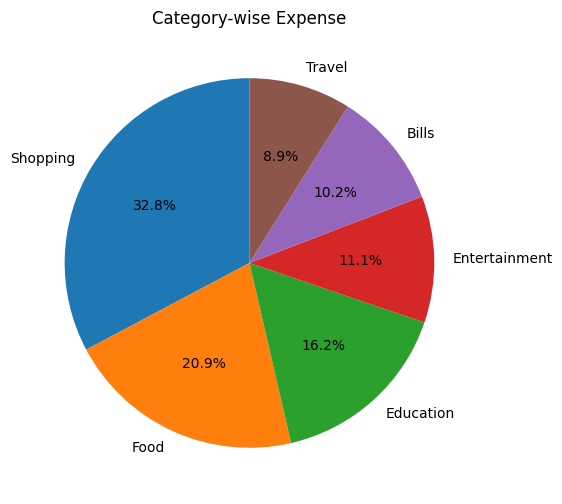

In [4]:
expense = df[df["Type"] == "Expense"]
category_exp = expense.groupby("Category")["Amount"].sum().sort_values(ascending=False)
print(category_exp)

plt.figure(figsize=(6, 6))
plt.pie(category_exp, labels=category_exp.index, autopct="%1.1f%%", startangle=90)
plt.title("Category-wise Expense")
plt.savefig(folder + "/category_pie.png", dpi=150, bbox_inches="tight")
plt.show()

Type     Expense  Income  Savings
Month                            
2026-09     7700   15000     7300
2026-10     9500   15000     5500
2026-11     6300   15000     8700


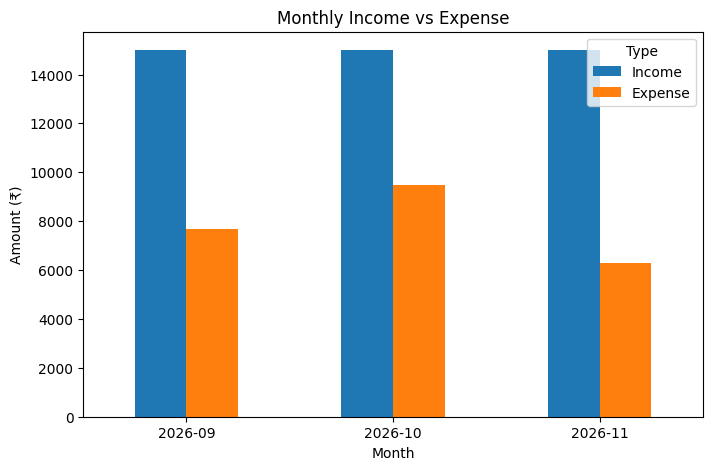

In [5]:
monthly = df.pivot_table(index="Month", columns="Type", values="Amount", aggfunc="sum").fillna(0)
monthly["Savings"] = monthly["Income"] - monthly["Expense"]
print(monthly)

monthly[["Income", "Expense"]].plot(kind="bar", figsize=(8, 5))
plt.title("Monthly Income vs Expense")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=0)
plt.savefig(folder + "/monthly_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
top_cat = category_exp.index[0]
print(f"सबसे ज़्यादा खर्च '{top_cat}' पर हुआ: ₹{category_exp.iloc[0]}")
print("सबसे ज़्यादा बचत वाला महीना:", monthly["Savings"].idxmax())

df.to_csv(folder + "/budget_data.csv", index=False)
print("CSV Drive में सेव हो गई")

सबसे ज़्यादा खर्च 'Shopping' पर हुआ: ₹7700
सबसे ज़्यादा बचत वाला महीना: 2026-11
CSV Drive में सेव हो गई


## Conclusion
- कुल आय ₹45,000 में से ₹23,500 खर्च हुए और ₹21,500 की बचत हुई (47.8%)।
- सबसे ज़्यादा खर्च Shopping पर हुआ (₹7,700)। इसे कम करके बचत और बढ़ाई जा सकती है।
- सबसे ज़्यादा बचत नवंबर 2026 में हुई, क्योंकि उस महीने खर्च सबसे कम रहा।
- हर महीने की आय ₹15,000 स्थिर रही, इसलिए बचत सिर्फ़ खर्च के हिसाब से बदली।